# Generacion y evaluacion de datos sinteticos con Iris

## Autor : Vladlen Shatunov

## 1. Introduccion

Los datos sinteticos son datos generados artificialmente mediante reglas, simulaciones o modelos estadisticos que buscan reproducir determinadas caracteristicas de los datos reales.

En aprendizaje automatico, estos datos pueden utilizarse para complementar conjuntos de entrenamiento, simular escenarios o desarrollar modelos cuando existen limitaciones relacionadas con la disponibilidad de informacion.

Sin embargo, generar datos artificiales no garantiza que sean adecuados para entrenar modelos. Es necesario evaluar si conservan patrones relevantes y si permiten obtener resultados satisfactorios al trabajar con datos reales.

### Objetivo

Generar datos sinteticos a partir del conjunto de datos Iris y evaluar su utilidad en un problema de clasificacion, comparando el rendimiento de un modelo entrenado con datos reales frente a otro entrenado con datos sinteticos.

### Metodologia

El experimento se desarrollara mediante las siguientes etapas:

1. Carga y exploracion del dataset Iris.
2. Separacion de los datos en entrenamiento y prueba.
3. Generacion de observaciones sinteticas mediante un metodo estadistico.
4. Comparacion de las caracteristicas de los datos reales y sinteticos.
5. Entrenamiento de modelos de clasificacion.
6. Evaluacion y comparacion de resultados.
7. Analisis de las limitaciones del experimento.

## 2. Importacion de librerias y carga de datos

Para desarrollar el experimento utilizaremos Python y algunas librerias especializadas en manipulacion de datos, calculos numericos, visualizacion y aprendizaje automatico.

El conjunto de datos seleccionado es Iris, disponible en Scikit-learn. Contiene mediciones de 150 flores pertenecientes a tres especies diferentes, con cuatro caracteristicas numericas por observacion.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

In [3]:
# Cargar el dataset Iris como un DataFrame
iris = load_iris(as_frame=True)

# Crear una copia de los datos
df = iris.frame.copy()

# Consultar las dimensiones y las clases
print("Dimensiones del dataset:", df.shape)
print("Especies:", iris.target_names)

# Visualizar las primeras cinco observaciones
df.head()

Dimensiones del dataset: (150, 5)
Especies: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 3. Exploracion inicial de los datos

Antes de generar observaciones sinteticas, es importante conocer las caracteristicas del conjunto de datos original.

En esta etapa se revisaran las estadisticas descriptivas, la presencia de valores faltantes y la distribucion de las especies.

Este analisis permitira identificar algunas propiedades de los datos reales que posteriormente podremos comparar con los datos sinteticos.

In [4]:
# Obtener estadisticas descriptivas de las variables numericas
df[iris.feature_names].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.84,0.83,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.06,0.44,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.76,1.77,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.20,0.76,0.1,0.3,1.30,1.8,2.5


In [5]:
# Verificar si existen valores faltantes
print("Valores faltantes por columna:")
print(df.isnull().sum())

Valores faltantes por columna:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [6]:
# Contar las observaciones de cada especie
conteo_clases = df["target"].value_counts().sort_index()

# Mostrar el nombre y la cantidad de cada especie
for i, especie in enumerate(iris.target_names):
    print(f"{especie}: {conteo_clases[i]} observaciones")

setosa: 50 observaciones
versicolor: 50 observaciones
virginica: 50 observaciones


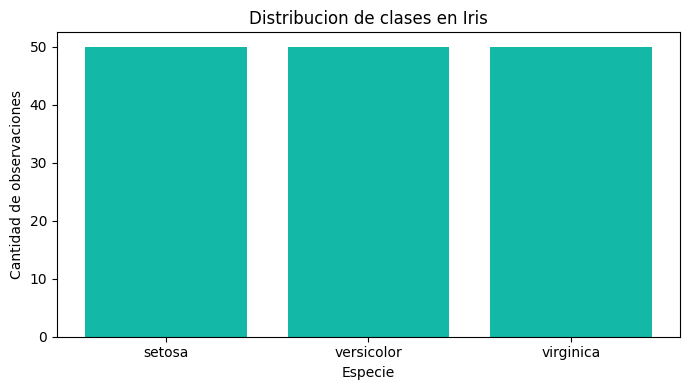

In [7]:
# Visualizar la cantidad de observaciones por especie
plt.figure(figsize=(7, 4))

plt.bar(
    iris.target_names,
    conteo_clases.values,
    color="#14B8A6"
)

plt.title("Distribucion de clases en Iris")
plt.xlabel("Especie")
plt.ylabel("Cantidad de observaciones")

plt.tight_layout()
plt.show()

### 3.1. Observaciones del analisis exploratorio

El conjunto de datos Iris contiene 150 observaciones distribuidas de manera equilibrada entre tres especies de flores.

Las cuatro caracteristicas numericas presentan diferentes rangos de valores y medidas de dispersion, lo que refleja las diferencias entre las dimensiones de los sepalos y petalos.

Adicionalmente, no se identificaron valores faltantes, por lo que no es necesario realizar imputacion.

Estas caracteristicas permiten utilizar el dataset para experimentar con la generacion de datos sinteticos y evaluar si es posible conservar las propiedades estadisticas de las observaciones originales.

## 4. Preparacion de los datos

Para desarrollar el experimento, primero se separan las variables predictoras (X) de la variable objetivo (y).

- **X:** contiene las cuatro medidas de los sepalos y petalos.
- **y:** contiene la especie de cada flor, representada mediante las clases 0, 1 y 2.

Posteriormente, el dataset se divide en dos conjuntos:

- **Entrenamiento (80 %):** se utiliza para aprender los parametros del generador de datos sinteticos y entrenar los modelos de clasificacion.
- **Prueba (20 %):** se reserva para evaluar el rendimiento de los modelos con observaciones reales no utilizadas durante el entrenamiento.

Se utiliza una division estratificada para conservar la proporcion de las tres especies en ambos conjuntos.

Ademas, se establece una semilla fija para garantizar que la division pueda reproducirse.

In [8]:
# Separar las variables predictoras y la variable objetivo
X = df[iris.feature_names].copy()
y = df["target"].copy()

# Verificar las dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)


In [9]:
from sklearn.model_selection import train_test_split

# Separar los datos en entrenamiento (80 %) y prueba (20 %)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=2026
)

# Verificar las dimensiones de los conjuntos
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [10]:
# Comprobar la distribucion de clases en cada conjunto
print("Distribucion en entrenamiento:")
print(y_train.value_counts().sort_index())

print("\nDistribucion en prueba:")
print(y_test.value_counts().sort_index())

Distribucion en entrenamiento:
target
0    40
1    40
2    40
Name: count, dtype: int64

Distribucion en prueba:
target
0    10
1    10
2    10
Name: count, dtype: int64


### 4.1. Resultados de la division

La division genero un conjunto de entrenamiento con 120 observaciones y un conjunto de prueba con 30 observaciones.

Gracias a la estratificacion, cada especie cuenta con 40 observaciones de entrenamiento y 10 de prueba.

Esta separacion permite evaluar los modelos utilizando datos reales que no participaron en el entrenamiento.

Para evitar Data Leakage, los parametros estadisticos utilizados durante la generacion de datos sinteticos se calcularan exclusivamente a partir del conjunto de entrenamiento.

El conjunto de prueba permanecera reservado hasta la etapa de evaluacion.

## 5. Generacion de datos sinteticos

Para generar los datos sinteticos se utilizara una distribucion normal multivariada, un metodo estadistico que permite crear nuevas observaciones a partir de las medias y covarianzas de un conjunto de datos.

La generacion se realizara de manera independiente para cada especie, con el objetivo de conservar sus principales caracteristicas y la distribucion de clases.

Se generara la misma cantidad de observaciones sinteticas que observaciones reales de entrenamiento: 40 por especie, para un total de 120.

Los parametros estadisticos se calcularan exclusivamente a partir de los datos de entrenamiento, evitando utilizar informacion del conjunto de prueba.

Este metodo representa una aproximacion estadistica sencilla y no garantiza reproducir todas las propiedades de los datos originales.

In [11]:
# Inicializar el generador con una semilla fija
rng = np.random.default_rng(2026)

# Listas para almacenar las observaciones y sus etiquetas
datos_sinteticos = []
etiquetas_sinteticas = []

# Generar datos sinteticos para cada especie
for clase in sorted(y_train.unique()):

    # Seleccionar las observaciones reales de la especie
    datos_clase = X_train.loc[y_train == clase]

    # Calcular la media y la matriz de covarianza
    media = datos_clase.mean().to_numpy()
    covarianza = datos_clase.cov().to_numpy()

    # Mantener la misma cantidad de observaciones por especie
    cantidad = len(datos_clase)

    # Generar nuevas observaciones
    muestras = rng.multivariate_normal(
        mean=media,
        cov=covarianza,
        size=cantidad
    )

    # Almacenar los datos sinteticos
    datos_sinteticos.append(
        pd.DataFrame(muestras, columns=X_train.columns)
    )

    # Asignar la especie correspondiente
    etiquetas_sinteticas.extend([clase] * cantidad)

# Unir las observaciones generadas
X_sintetico = pd.concat(
    datos_sinteticos,
    ignore_index=True
)

# Crear la variable objetivo sintetica
y_sintetico = pd.Series(
    etiquetas_sinteticas,
    name="target"
)

In [12]:
# Verificar las dimensiones de los datos sinteticos
print("Dimensiones de X_sintetico:", X_sintetico.shape)
print("Dimensiones de y_sintetico:", y_sintetico.shape)

# Verificar la distribucion de clases
print("\nObservaciones sinteticas por especie:")
print(y_sintetico.value_counts().sort_index())

# Mostrar las primeras observaciones generadas
X_sintetico.head().round(2)

Dimensiones de X_sintetico: (120, 4)
Dimensiones de y_sintetico: (120,)

Observaciones sinteticas por especie:
target
0    40
1    40
2    40
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.19,3.81,1.76,0.40
1,4.76,3.26,1.45,0.25
2,5.14,3.54,1.34,0.28
3,5.06,3.47,1.43,0.19
4,5.23,3.53,1.55,0.15


In [13]:
# Identificar medidas sinteticas menores o iguales a cero
valores_no_positivos = (X_sintetico <= 0).sum()

print("Valores no positivos por caracteristica:")
print(valores_no_positivos)

Valores no positivos por caracteristica:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


### 5.1. Resultados de la generacion

Se generaron 120 observaciones sinteticas utilizando las medias y matrices de covarianza calculadas a partir del conjunto de entrenamiento.

Los datos generados contienen las mismas cuatro caracteristicas del dataset original y mantienen una distribucion equilibrada de 40 observaciones por especie.

La utilizacion de una semilla fija permite reproducir el proceso de generacion.

Aunque las observaciones sinteticas se obtienen a partir de las propiedades estadisticas de los datos reales, es necesario comprobar que sus distribuciones y relaciones sean suficientemente similares.

Esta comparacion se realizara en la siguiente etapa.

## 6. Comparacion de datos reales y sinteticos

Una vez generados los datos sinteticos, es necesario evaluar si conservan las principales caracteristicas estadisticas de los datos originales.

Para ello, se compararan las medias, desviaciones estandar y distribuciones de las observaciones reales y sinteticas.

El analisis se realizara utilizando los datos reales de entrenamiento, sin incluir el conjunto de prueba reservado.

Se prestara especial atencion a la longitud y anchura de los petalos, ya que estas variables permiten visualizar las diferencias entre las especies.

In [14]:
# Variables seleccionadas para la comparacion
variables = ["petal length (cm)", "petal width (cm)"]

# Almacenar las estadisticas de cada especie
registros = []

for clase, especie in enumerate(iris.target_names):

    # Comparar los dos conjuntos de datos
    for origen, X_datos, y_datos in [
        ("Real", X_train, y_train),
        ("Sintetico", X_sintetico, y_sintetico)
    ]:

        # Seleccionar las observaciones correspondientes
        datos_clase = X_datos.loc[y_datos == clase, variables]

        # Calcular estadisticas descriptivas
        registros.append({
            "Especie": especie,
            "Origen": origen,
            "Media longitud": datos_clase[variables[0]].mean(),
            "Desv. longitud": datos_clase[variables[0]].std(),
            "Media anchura": datos_clase[variables[1]].mean(),
            "Desv. anchura": datos_clase[variables[1]].std()
        })

# Crear la tabla comparativa
comparacion = pd.DataFrame(registros)

comparacion.round(2)

,Especie,Origen,Media longitud,Desv. longitud,Media anchura,Desv. anchura
0,setosa,Real,1.46,0.18,0.24,0.09
1,setosa,Sintetico,1.48,0.17,0.25,0.10
2,versicolor,Real,4.30,0.47,1.35,0.19
3,versicolor,Sintetico,4.18,0.59,1.28,0.23
4,virginica,Real,5.58,0.56,2.05,0.27
5,virginica,Sintetico,5.59,0.61,1.97,0.26


### 6.1. Comparacion visual de las distribuciones

Los graficos de dispersion permiten observar como se relacionan dos variables numericas y como se agrupan las observaciones.

Se representaran la longitud y anchura de los petalos para comparar los patrones presentes en los datos reales y sinteticos.

Ambos graficos utilizaran las mismas escalas para facilitar una comparacion directa.

Los colores diferenciaran el origen de los datos y los marcadores permitiran distinguir las tres especies.

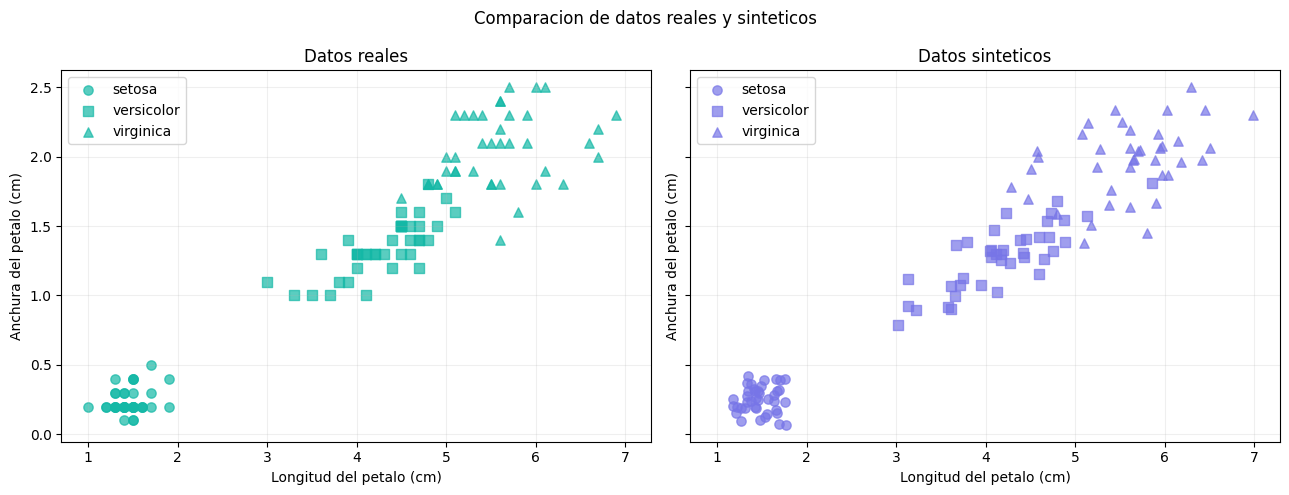

In [15]:
# Configurar los conjuntos que vamos a comparar
conjuntos = [
    ("Datos reales", X_train, y_train, "#14B8A6"),
    ("Datos sinteticos", X_sintetico, y_sintetico, "#7775E7")
]

# Marcadores diferentes para cada especie
marcadores = ["o", "s", "^"]

# Crear los dos graficos
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharex=True,
    sharey=True
)

for ax, (titulo, X_datos, y_datos, color) in zip(axes, conjuntos):

    for clase, especie in enumerate(iris.target_names):

        # Seleccionar las flores de cada especie
        datos_clase = X_datos.loc[y_datos == clase]

        ax.scatter(
            datos_clase["petal length (cm)"],
            datos_clase["petal width (cm)"],
            label=especie,
            color=color,
            marker=marcadores[clase],
            alpha=0.7,
            s=45
        )

    ax.set_title(titulo)
    ax.set_xlabel("Longitud del petalo (cm)")
    ax.set_ylabel("Anchura del petalo (cm)")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle("Comparacion de datos reales y sinteticos")
plt.tight_layout()
plt.show()

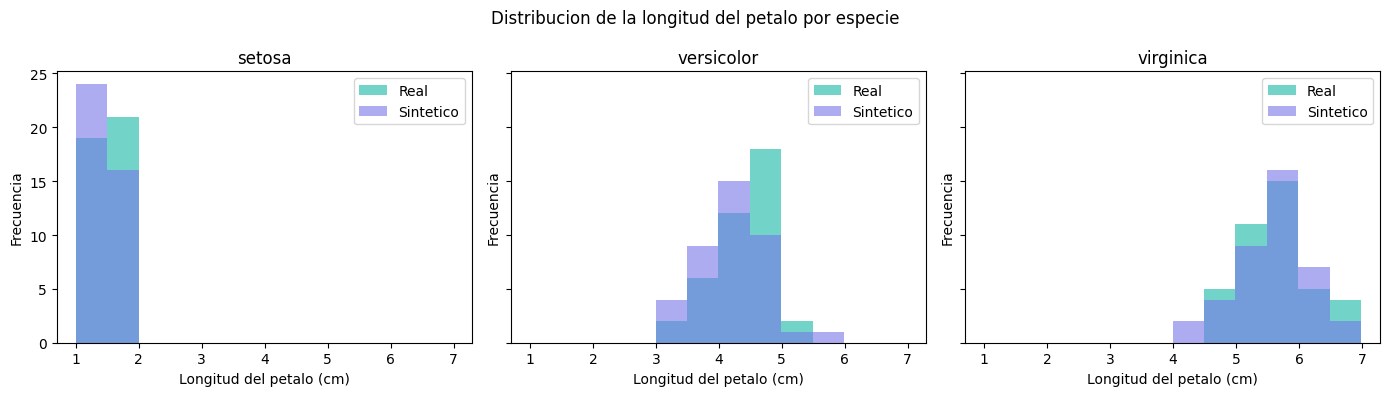

In [16]:
# Seleccionar la caracteristica que vamos a comparar
variable = "petal length (cm)"

# Definir intervalos comunes para ambos conjuntos
valores = pd.concat([
    X_train[variable],
    X_sintetico[variable]
])

intervalos = np.linspace(valores.min(), valores.max(), 13)

# Crear un histograma por especie
fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4),
    sharex=True,
    sharey=True
)

for clase, especie in enumerate(iris.target_names):

    # Seleccionar observaciones reales y sinteticas
    reales = X_train.loc[y_train == clase, variable]
    sinteticos = X_sintetico.loc[y_sintetico == clase, variable]

    axes[clase].hist(
        reales,
        bins=intervalos,
        alpha=0.6,
        color="#14B8A6",
        label="Real"
    )

    axes[clase].hist(
        sinteticos,
        bins=intervalos,
        alpha=0.6,
        color="#7775E7",
        label="Sintetico"
    )

    axes[clase].set_title(especie)
    axes[clase].set_xlabel("Longitud del petalo (cm)")
    axes[clase].set_ylabel("Frecuencia")
    axes[clase].legend()

plt.suptitle("Distribucion de la longitud del petalo por especie")
plt.tight_layout()
plt.show()

### 6.2. Interpretacion de resultados

La comparacion visual permite observar que los datos sinteticos conservan aproximadamente los patrones presentes en las observaciones reales.

En los graficos de dispersion se identifican agrupaciones similares para las tres especies. Setosa mantiene una separacion clara, mientras que versicolor y virginica presentan cierto solapamiento en ambos conjuntos.

Los histogramas muestran que la longitud de los petalos sinteticos se distribuye en rangos similares a los originales, aunque existen diferencias en las frecuencias de algunos intervalos.

Estos resultados sugieren que el generador estadistico logro representar algunas caracteristicas relevantes del dataset.

Sin embargo, la similitud visual no garantiza que los datos sinteticos sean igualmente utiles para entrenar modelos de aprendizaje automatico.

Para evaluar su utilidad, se entrenaran dos clasificadores utilizando datos reales y sinteticos por separado.

## 7. Entrenamiento de modelos de clasificacion

Para evaluar la utilidad de los datos sinteticos se utilizara el algoritmo K-Nearest Neighbors (KNN).

Este algoritmo clasifica nuevas observaciones considerando las clases de sus vecinos mas cercanos dentro del conjunto de entrenamiento.

Se utilizaran tres vecinos (K=3) y se entrenaran dos modelos independientes:

- **Modelo A:** entrenado con observaciones reales.
- **Modelo B:** entrenado con observaciones sinteticas.

Ambos modelos utilizaran el mismo algoritmo y los mismos parametros para facilitar una comparacion justa.

Antes del entrenamiento se aplicara una estandarizacion de las caracteristicas mediante StandardScaler, ya que KNN utiliza distancias entre observaciones.

Para evitar Data Leakage, cada modelo utilizara un Pipeline que ajustara la estandarizacion exclusivamente con sus respectivos datos de entrenamiento.

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Modelo entrenado con datos reales
modelo_real = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

# Modelo entrenado con datos sinteticos
modelo_sintetico = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

In [18]:
# Entrenar el modelo A con observaciones reales
modelo_real.fit(X_train, y_train)

# Entrenar el modelo B con observaciones sinteticas
modelo_sintetico.fit(X_sintetico, y_sintetico)

print("Entrenamiento de ambos modelos completado.")

Entrenamiento de ambos modelos completado.


## 8. Evaluacion de los modelos

Una vez entrenados los clasificadores, se evaluara su rendimiento utilizando las 30 observaciones reales del conjunto de prueba.

Ambos modelos realizaran predicciones sobre exactamente las mismas flores, permitiendo comparar su capacidad de generalizacion.

Para evaluar el rendimiento se utilizaran las siguientes metricas:

- **Accuracy:** proporcion de observaciones clasificadas correctamente.
- **F1-score macro:** promedio del F1-score de cada clase, considerando tanto precision como recall.
- **Matriz de confusion:** muestra la cantidad de predicciones correctas e incorrectas para cada especie.

El conjunto de prueba no fue utilizado para ajustar los modelos ni para generar los datos sinteticos.

In [19]:
# Generar predicciones sobre el mismo conjunto de prueba
pred_real = modelo_real.predict(X_test)
pred_sintetico = modelo_sintetico.predict(X_test)

# Comparar las primeras diez predicciones
comparacion_predicciones = pd.DataFrame({
    "Valor real": y_test.to_numpy(),
    "Modelo real": pred_real,
    "Modelo sintetico": pred_sintetico
})

comparacion_predicciones.head(10)

,Valor real,Modelo real,Modelo sintetico
0,0,0,0
1,0,0,0
2,1,2,1
3,1,1,1
4,0,0,0
5,2,1,2
6,0,0,0
7,2,2,2
8,1,1,1
9,0,0,0


In [20]:
from sklearn.metrics import accuracy_score, f1_score

# Calcular las metricas del modelo real
accuracy_real = accuracy_score(y_test, pred_real)
f1_real = f1_score(y_test, pred_real, average="macro")

# Calcular las metricas del modelo sintetico
accuracy_sintetico = accuracy_score(y_test, pred_sintetico)
f1_sintetico = f1_score(y_test, pred_sintetico, average="macro")

# Crear una tabla comparativa
resultados = pd.DataFrame({
    "Modelo": ["Datos reales", "Datos sinteticos"],
    "Accuracy": [accuracy_real, accuracy_sintetico],
    "F1 macro": [f1_real, f1_sintetico]
})

# Mostrar los resultados
resultados.round(4)

,Modelo,Accuracy,F1 macro
0,Datos reales,0.9000,0.8997
1,Datos sinteticos,0.9333,0.9327


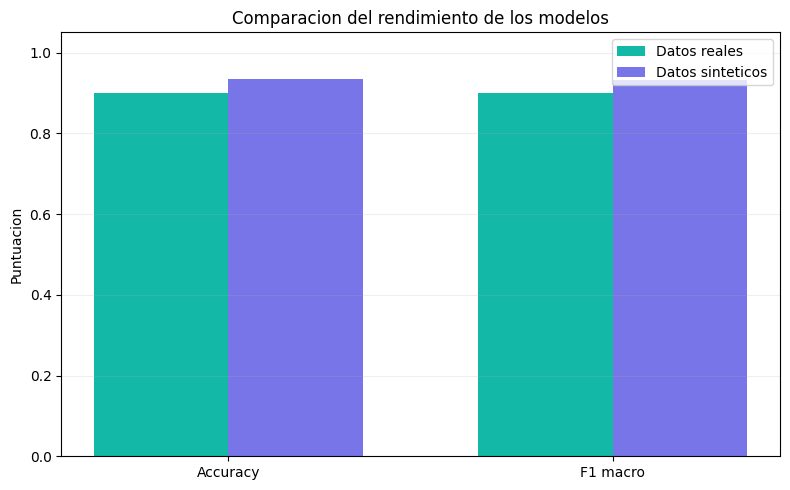

In [21]:
# Preparar las posiciones de las barras
metricas = ["Accuracy", "F1 macro"]
posiciones = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

# Barras del modelo entrenado con datos reales
ax.bar(
    posiciones - ancho / 2,
    [accuracy_real, f1_real],
    width=ancho,
    label="Datos reales",
    color="#14B8A6"
)

# Barras del modelo entrenado con datos sinteticos
ax.bar(
    posiciones + ancho / 2,
    [accuracy_sintetico, f1_sintetico],
    width=ancho,
    label="Datos sinteticos",
    color="#7775E7"
)

ax.set_xticks(posiciones)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Puntuacion")
ax.set_title("Comparacion del rendimiento de los modelos")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### 8.1. Analisis mediante matrices de confusion

Las matrices de confusion permiten identificar como se distribuyen los aciertos y errores de clasificacion entre las diferentes especies.

Cada fila representa la clase real y cada columna la clase predicha.

Los valores de la diagonal principal corresponden a predicciones correctas, mientras que los valores fuera de la diagonal representan errores.

Se compararan las matrices de ambos modelos para identificar posibles diferencias en su comportamiento.

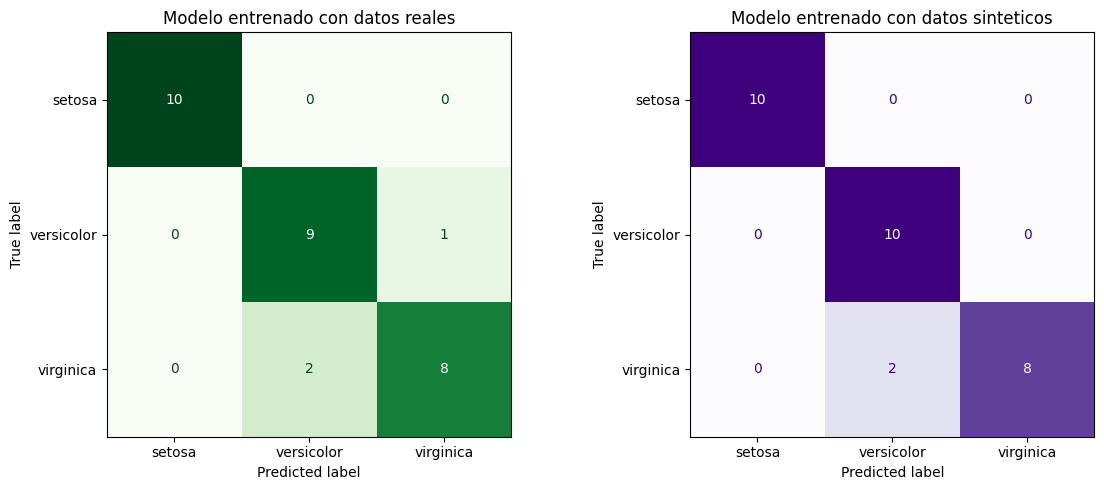

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

# Crear una figura para comparar los modelos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de confusion del modelo real
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_real,
    labels=[0, 1, 2],
    display_labels=iris.target_names,
    cmap="Greens",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title("Modelo entrenado con datos reales")

# Matriz de confusion del modelo sintetico
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_sintetico,
    labels=[0, 1, 2],
    display_labels=iris.target_names,
    cmap="Purples",
    colorbar=False,
    ax=axes[1]
)

axes[1].set_title("Modelo entrenado con datos sinteticos")

plt.tight_layout()
plt.show()

### 8.2. Interpretacion de resultados

Los resultados muestran que ambos modelos obtuvieron un rendimiento elevado al clasificar las 30 observaciones reales del conjunto de prueba.

El modelo entrenado con datos reales alcanzo un Accuracy del 90,00 % y un F1 macro de 0,8997, clasificando correctamente 27 de las 30 observaciones.

Por su parte, el modelo entrenado con datos sinteticos obtuvo un Accuracy del 93,33 % y un F1 macro de 0,9327, con 28 observaciones correctamente clasificadas.

Las matrices de confusion muestran que ambos modelos clasificaron correctamente todas las observaciones de setosa. La principal diferencia se encuentra en versicolor, donde el modelo sintetico obtuvo un acierto adicional. Ambos modelos confundieron dos observaciones de virginica con versicolor.

Estos resultados sugieren que los datos sinteticos generados conservaron patrones relevantes para el problema de clasificacion.

Sin embargo, la diferencia de rendimiento corresponde a una sola observacion. Debido al tamaño reducido del conjunto de prueba, no es posible concluir que el entrenamiento con datos sinteticos sea superior al entrenamiento con datos reales.

Para obtener una evaluacion mas confiable, resulta conveniente repetir el experimento utilizando diferentes particiones de los datos.

## 9. Evaluacion de estabilidad

Los resultados anteriores se obtuvieron utilizando una unica division de entrenamiento y prueba. Por lo tanto, pueden estar influenciados por las observaciones seleccionadas en cada conjunto.

Para evaluar la estabilidad del rendimiento, se repetira el experimento utilizando 30 divisiones estratificadas diferentes.

En cada repeticion se realizaran las siguientes operaciones:

1. Dividir los datos reales en entrenamiento y prueba.
2. Calcular los parametros estadisticos utilizando solamente el entrenamiento.
3. Generar un nuevo conjunto de datos sinteticos.
4. Entrenar dos clasificadores KNN independientes.
5. Evaluar ambos modelos sobre el mismo conjunto de prueba real.

Finalmente, se compararan las medias y desviaciones estandar de Accuracy y F1 macro.

Este procedimiento permite estudiar la variabilidad de los resultados, aunque no garantiza que las diferencias observadas sean estadisticamente significativas.

In [23]:
def generar_datos_sinteticos(X_train, y_train, semilla):

    # Inicializar el generador aleatorio
    rng = np.random.default_rng(semilla)

    datos_generados = []
    etiquetas_generadas = []

    # Generar observaciones para cada especie
    for clase in sorted(y_train.unique()):

        # Seleccionar las observaciones de entrenamiento
        datos_clase = X_train.loc[y_train == clase]

        # Calcular los parametros estadisticos
        media = datos_clase.mean().to_numpy()
        covarianza = datos_clase.cov().to_numpy()

        # Generar la misma cantidad de observaciones
        muestras = rng.multivariate_normal(
            mean=media,
            cov=covarianza,
            size=len(datos_clase)
        )

        # Almacenar los datos y sus etiquetas
        datos_generados.append(
            pd.DataFrame(muestras, columns=X_train.columns)
        )

        etiquetas_generadas.extend(
            [clase] * len(datos_clase)
        )

    # Construir los conjuntos sinteticos
    X_sint = pd.concat(datos_generados, ignore_index=True)
    y_sint = pd.Series(etiquetas_generadas, name="target")

    return X_sint, y_sint

In [24]:
from sklearn.model_selection import StratifiedShuffleSplit

# Configurar 30 divisiones estratificadas
validacion = StratifiedShuffleSplit(
    n_splits=30,
    test_size=0.2,
    random_state=2026
)

resultados_repetidos = []

# Ejecutar el experimento para cada division
for repeticion, (idx_train, idx_test) in enumerate(
    validacion.split(X, y)
):

    # Separar entrenamiento y prueba
    X_train_rep = X.iloc[idx_train]
    X_test_rep = X.iloc[idx_test]

    y_train_rep = y.iloc[idx_train]
    y_test_rep = y.iloc[idx_test]

    # Generar datos sinteticos usando solo entrenamiento
    X_sint_rep, y_sint_rep = generar_datos_sinteticos(
        X_train_rep,
        y_train_rep,
        semilla=2026 + repeticion
    )

    # Crear modelos independientes
    modelo_A = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    )

    modelo_B = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    )

    # Entrenar cada modelo
    modelo_A.fit(X_train_rep, y_train_rep)
    modelo_B.fit(X_sint_rep, y_sint_rep)

    # Evaluar sobre los mismos datos reales de prueba
    pred_A = modelo_A.predict(X_test_rep)
    pred_B = modelo_B.predict(X_test_rep)

    # Registrar los resultados
    for nombre, predicciones in [
        ("Datos reales", pred_A),
        ("Datos sinteticos", pred_B)
    ]:

        resultados_repetidos.append({
            "Repeticion": repeticion + 1,
            "Modelo": nombre,
            "Accuracy": accuracy_score(
                y_test_rep, predicciones
            ),
            "F1 macro": f1_score(
                y_test_rep,
                predicciones,
                average="macro"
            )
        })

# Organizar los resultados
df_repeticiones = pd.DataFrame(resultados_repetidos)

df_repeticiones.head(10).round(4)

,Repeticion,Modelo,Accuracy,F1 macro
0,1,Datos reales,0.9000,0.8997
1,1,Datos sinteticos,0.9333,0.9327
2,2,Datos reales,0.9333,0.9333
3,2,Datos sinteticos,0.9333,0.9327
4,3,Datos reales,0.9333,0.9327
5,3,Datos sinteticos,0.9333,0.9327
6,4,Datos reales,0.9333,0.9327
7,4,Datos sinteticos,0.9667,0.9666
8,5,Datos reales,0.9000,0.8997
9,5,Datos sinteticos,0.9667,0.9666


In [25]:
# Calcular estadisticas de las 30 repeticiones
resumen = (
    df_repeticiones
    .groupby("Modelo")[["Accuracy", "F1 macro"]]
    .agg(["mean", "std"])
)

print("Resumen de las 30 repeticiones:")
display(resumen.round(4))

Resumen de las 30 repeticiones:


Accuracy         F1 macro        
                     mean     std     mean     std
Modelo                                            
Datos reales       0.9333  0.0401   0.9332  0.0403
Datos sinteticos   0.9456  0.0376   0.9451  0.0382

In [26]:
# Organizar el Accuracy por repeticion y modelo
comparacion_accuracy = df_repeticiones.pivot(
    index="Repeticion",
    columns="Modelo",
    values="Accuracy"
)

# Comparar los resultados de cada repeticion
real = comparacion_accuracy["Datos reales"]
sintetico = comparacion_accuracy["Datos sinteticos"]

print("Repeticiones con mayor Accuracy:")

print("Modelo real:", (real > sintetico).sum())
print("Modelo sintetico:", (sintetico > real).sum())
print("Empates:", (real == sintetico).sum())

Repeticiones con mayor Accuracy:
Modelo real: 3
Modelo sintetico: 12
Empates: 15


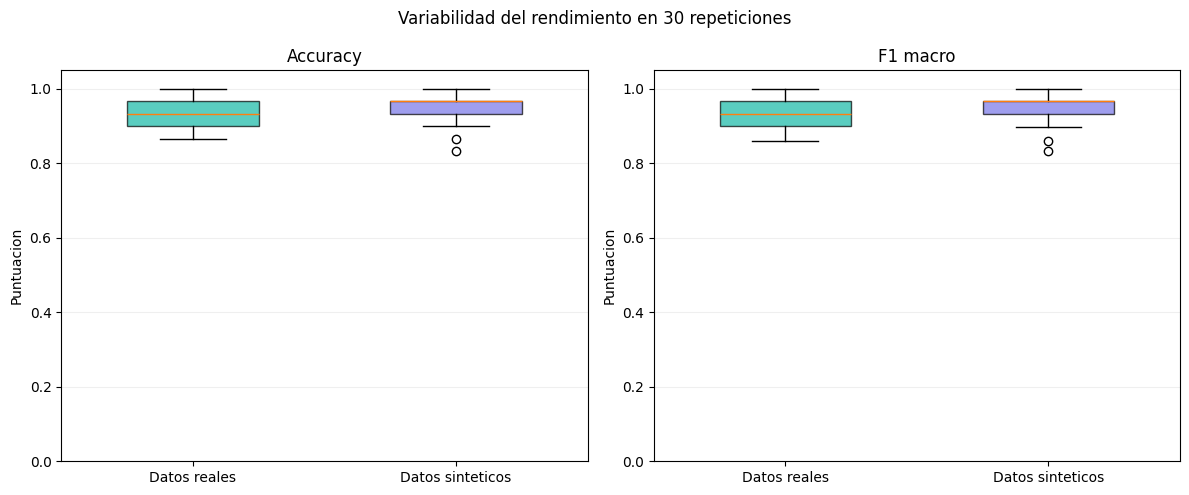

In [27]:
# Crear los graficos de distribucion de las metricas
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colores = ["#14B8A6", "#7775E7"]
modelos = ["Datos reales", "Datos sinteticos"]

for ax, metrica in zip(axes, ["Accuracy", "F1 macro"]):

    # Obtener resultados de cada modelo
    valores = [
        df_repeticiones.loc[
            df_repeticiones["Modelo"] == modelo,
            metrica
        ]
        for modelo in modelos
    ]

    # Crear el diagrama de caja
    grafico = ax.boxplot(
        valores,
        patch_artist=True,
        widths=0.5
    )

    # Aplicar los colores de cada conjunto
    for caja, color in zip(grafico["boxes"], colores):
        caja.set_facecolor(color)
        caja.set_alpha(0.7)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(modelos)
    ax.set_title(metrica)
    ax.set_ylabel("Puntuacion")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.2)

plt.suptitle("Variabilidad del rendimiento en 30 repeticiones")
plt.tight_layout()
plt.show()

### 9.1. Interpretacion de resultados

Los resultados de las 30 repeticiones muestran que ambos modelos mantienen un rendimiento elevado en la clasificacion de las especies del dataset Iris.

El modelo entrenado con datos reales obtuvo un Accuracy promedio de 93,33 % y un F1 macro de 0,9332. Por su parte, el modelo entrenado con datos sinteticos alcanzo un Accuracy promedio de 94,56 % y un F1 macro de 0,9451.

Las desviaciones estandar del Accuracy fueron de 0,0401 para el modelo real y 0,0376 para el sintetico, indicando una variabilidad ligeramente menor en este ultimo.

Al comparar individualmente las 30 repeticiones, el modelo real obtuvo mayor Accuracy en 3 ocasiones, el sintetico en 12 y ambos empataron en 15.

Los diagramas de caja muestran distribuciones de rendimiento similares y un solapamiento considerable entre ambos modelos.

Estos resultados sugieren que los datos sinteticos generados mediante el metodo estadistico conservaron informacion relevante para el entrenamiento de modelos de clasificacion.

Sin embargo, las diferencias observadas son relativamente pequeñas y las divisiones utilizadas comparten observaciones entre repeticiones. Por lo tanto, los resultados no permiten afirmar que el entrenamiento con datos sinteticos sea estadisticamente superior.

El experimento demuestra que, bajo las condiciones evaluadas, los datos sinteticos pueden proporcionar un rendimiento comparable al obtenido con datos reales.

## 10. Limitaciones y conclusiones

### 10.1. Limitaciones del experimento

Aunque los resultados obtenidos fueron satisfactorios, es importante reconocer algunas limitaciones de la metodologia utilizada.

**1. Tamaño del dataset**

Iris contiene solamente 150 observaciones, de las cuales 120 fueron utilizadas para entrenamiento y 30 para prueba. Este tamaño reducido limita la cantidad de informacion disponible para estimar las distribuciones y evaluar los modelos.

**2. Metodo de generacion**

La generacion de datos sinteticos se realizo mediante distribuciones normales multivariadas ajustadas por especie. Este metodo permite conservar ciertas propiedades estadisticas, pero supone una estructura de distribucion que puede no representar completamente los patrones originales.

Ademas, las distribuciones normales no imponen limites fisicos, por lo que pueden producir valores que no sean validos para determinadas variables.

**3. Dependencia de los datos originales**

El generador necesita observaciones reales y sus etiquetas para calcular los parametros estadisticos de cada especie. Por lo tanto, este procedimiento no elimina la necesidad de disponer de datos originales.

**4. Evaluacion del rendimiento**

Aunque se realizaron 30 divisiones estratificadas, las particiones no son independientes y pueden compartir observaciones. Por esta razon, los resultados permiten analizar la estabilidad del rendimiento, pero no demostrar superioridad estadistica entre los modelos.

**5. Privacidad de los datos**

La generacion de datos sinteticos no garantiza automaticamente la privacidad de las observaciones originales. Dependiendo del metodo utilizado, los datos generados pueden conservar informacion que permita revelar caracteristicas de los registros de entrenamiento.

### 10.2. Conclusiones

El experimento permitio generar y evaluar datos sinteticos a partir del conjunto de datos Iris, utilizando un metodo estadistico basado en medias y matrices de covarianza por especie.

La comparacion estadistica y visual mostro que las observaciones generadas conservaron aproximadamente las agrupaciones, distribuciones y relaciones presentes en los datos reales.

En la evaluacion inicial, el modelo entrenado con datos reales obtuvo un Accuracy del 90,00 %, mientras que el modelo entrenado con datos sinteticos alcanzo un 93,33 %. Esta diferencia correspondio a una sola observacion adicional clasificada correctamente.

Posteriormente, al repetir el experimento con 30 divisiones estratificadas, se obtuvieron los siguientes resultados:

- **Datos reales:** Accuracy promedio de 93,33 % y F1 macro de 0,9332.
- **Datos sinteticos:** Accuracy promedio de 94,56 % y F1 macro de 0,9451.

Aunque el modelo sintetico presento un rendimiento promedio ligeramente superior, las diferencias fueron pequeñas y existio un solapamiento considerable entre las distribuciones de rendimiento.

Los resultados muestran que los datos sinteticos generados mediante este procedimiento conservaron informacion relevante para entrenar un clasificador con un rendimiento comparable al obtenido con datos reales.

Sin embargo, su utilidad depende de la calidad del proceso de generacion, de las caracteristicas del conjunto original y de las condiciones del problema.

En conclusion, los datos sinteticos representan una alternativa que puede complementar los datos reales en proyectos de aprendizaje automatico, siempre que su fidelidad, utilidad y posibles riesgos sean evaluados adecuadamente.

## 11. Referencias y reproducibilidad

### 11.1. Referencias

Las siguientes fuentes proporcionan documentacion sobre las herramientas y los conceptos utilizados durante el experimento.

**Scikit-learn**

- [Iris Dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html). Documentacion del conjunto de datos Iris.
- [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html). Implementacion del algoritmo KNN.
- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html). Construccion de procesos de entrenamiento con transformaciones.
- [StratifiedShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedShuffleSplit.html). Divisiones estratificadas para la evaluacion de modelos.

**NumPy**

- [Generator.multivariate_normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.multivariate_normal.html). Generacion de observaciones mediante distribuciones normales multivariadas.

**National Institute of Standards and Technology (NIST)**

- [SDNist: Synthetic Data Report Tool](https://www.nist.gov/services-resources/software/sdnist-synthetic-data-report-tool). Herramienta para evaluar propiedades de utilidad y privacidad de datos sinteticos.

### 11.2. Entorno de ejecucion

El experimento fue desarrollado en Python utilizando NumPy, Pandas, Matplotlib y Scikit-learn.

Se utilizaron semillas fijas para controlar la aleatoriedad durante la division de los datos y la generacion de observaciones sinteticas.

A continuacion se presentan las versiones de las librerias utilizadas, con el fin de facilitar la reproduccion del experimento en otros entornos.

In [28]:
import sys
import sklearn
import matplotlib

# Mostrar las versiones del entorno utilizado
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.16
NumPy: 2.1.3
Pandas: 2.2.3
Matplotlib: 3.10.0
Scikit-learn: 1.6.1
